## 1. Imports and Configuration

In [5]:
# %pip install pydicom monai simpleitk --break-system-packages

In [6]:
%pip install monai --no-deps

Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install pydicom

Note: you may need to restart the kernel to use updated packages.


In [8]:
# [IMPORTS]
import os
import numpy as np
import pandas as pd
import torch
import monai.transforms as mt
import pydicom
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import nibabel as nib
from monai.transforms import Compose, SpatialCropd, SpatialPadd

In [9]:
# [CONFIG]
KL_DIVERGENCE = '../../data/baseline/kl_divergence_beta_5.00e-05.csv'
CHECKPOINT_PATH = '../../models/checkpoints/beta_5.00e-05_best.pth'
MASK_PATH = '../../data/masks/rmask_ICV.nii'
IMAGES_ROOT     = '../../data/raw/ppmi_images'  # parent folder of PD/Cont/SWEDD
OUTPUT_DIR      = '../../results/augmentation/'
FIGURES_DIR     = '../../results/figures/'
os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

N_SUBJECTS   = 100
RANDOM_STATE = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Images root: {IMAGES_ROOT}")

Device: cpu
Checkpoint: ../../models/checkpoints/beta_5.00e-05_best.pth
Images root: ../../data/raw/ppmi_images


## 2. Load Model

The β-VAE was trained by Professor Presotto and saved as beta_5.00e-05_best.pth. I copied selected_model.py from the training repository into our project to access the decoder and wrapper classes.

The encoder required a custom definition (CustomEncoder) because the checkpoint architecture differs slightly from the original BottleneckEncoder — specifically it has no channel reduction blocks. The encoder outputs a 512-dimensional vector which BottleneckAE splits into a 256-dimensional mean (mu) and log-variance. During inference only mu is used, giving a deterministic 256-dimensional latent representation per scan.

In [10]:
# Check the Checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
encoder_keys = [k for k in checkpoint.keys() if 'encoder' in k]
for k in encoder_keys:
    print(k, checkpoint[k].shape)

encoder.backbone.down1.0.block.conv.weight torch.Size([32, 1, 3, 3, 3])
encoder.backbone.down1.0.block.conv.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.weight torch.Size([32])
encoder.backbone.down1.0.block.bn.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.0.block.bn.running_var torch.Size([32])
encoder.backbone.down1.0.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down1.1.block.conv.weight torch.Size([32, 32, 3, 3, 3])
encoder.backbone.down1.1.block.conv.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.weight torch.Size([32])
encoder.backbone.down1.1.block.bn.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.1.block.bn.running_var torch.Size([32])
encoder.backbone.down1.1.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down2.0.block.conv.weight torch.Size([64, 32, 3, 3, 3])
encoder.backbone.down2.0.block.conv.bias torch

In [11]:
# Check the KL Divergence
df_kl = pd.read_csv(KL_DIVERGENCE)
print(f"Total dimensions: {len(df_kl)}")
print(df_kl.head())

Total dimensions: 256
  dimension   mean_kl
0  latent_0  0.013907
1  latent_1  0.004226
2  latent_2  0.122685
3  latent_3  0.096220
4  latent_4  0.013870


In [12]:
import torch.nn as nn

# [VAE-WRAPPER]
# ─────────────────────────────────────────────────────────────────
# BottleneckAE.forward passes the full encoder output directly to
# the decoder. Since our CustomEncoder returns (mu, log_var), we
# need a wrapper that:
# 1. Extracts only mu for the decoder (deterministic inference)
# 2. Exposes an encode() method that returns mu directly
# ─────────────────────────────────────────────────────────────────

class VAEWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def encode(self, x):
        out = self.model.encoder(x)
        mu = out[0] if isinstance(out, (tuple, list)) else out
        return mu  # shape (1, 256)

    def decode(self, z):
        # conv_transpose3d needs (B, C, D, H, W) — reshape flat latent to (B, 256, 1, 1, 1)
        if z.dim() == 2:
            z = z.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)  # → (1, 256, 1, 1, 1)
        return self.model.decoder(z)

    def forward(self, x):
        mu = self.encode(x)
        recon = self.decode(mu)
        return recon, mu

In [14]:
import sys
sys.path.append('../../models')
import importlib
import autoencoder.custom_encoder
importlib.reload(autoencoder.custom_encoder)
from autoencoder.custom_encoder import CustomEncoder
from autoencoder.selected_model import (
    BottleneckAE, ComplexBottleneckDeconvDecoder
)


def load_model(checkpoint_path, device='cpu'):
    encoder = CustomEncoder(initial_filters=32, latent_dim=256)
    decoder = ComplexBottleneckDeconvDecoder(latent_dim=256, target_shape=(64, 128, 128))
    base    = BottleneckAE(encoder, decoder)
    ckpt    = torch.load(checkpoint_path, map_location=device)
    base.load_state_dict(ckpt)
    base.eval()
    wrapped = VAEWrapper(base)
    wrapped.eval()
    wrapped.to(device)
    # quick smoke test — catches tuple-to-decoder bug immediately
    dummy = torch.zeros(1, 1, 64, 128, 128, device=device)
    with torch.no_grad():
        recon, mu = wrapped(dummy)
    assert isinstance(recon, torch.Tensor), "decoder returned non-Tensor"
    assert isinstance(mu,    torch.Tensor), "encoder returned non-Tensor mu"
    print(f"Smoke test passed  recon {tuple(recon.shape)}  mu {tuple(mu.shape)}")
    return wrapped

model = load_model(CHECKPOINT_PATH, DEVICE)
vae = VAEWrapper(model)
vae.eval()
print("VAEWrapper ready")
# print(f"Encode output dim: 256")

Smoke test passed  recon (1, 1, 64, 128, 128)  mu (1, 256)
VAEWrapper ready


## 3. Load Images and Select 100 Subjects

In [15]:
# [LOAD-IMAGES]

IMAGE_ROOT = Path(IMAGES_ROOT)
GROUPS = {
    'PD':    IMAGE_ROOT / 'PPMI_Images_PD',
    'HC':    IMAGE_ROOT / 'PPMI_Images_Cont',
    'SWEDD': IMAGE_ROOT / 'PPMI_Images_SWEDD'
}

def find_dcm_files(root_dir, label):
    """Recursively find all .dcm files and extract PATNO."""
    records = []
    for dcm_path in Path(root_dir).rglob('*.dcm'):
     #   print(dcm_path)
        parts = dcm_path.parts
        # PATNO is the first subfolder under the group root
        relative = dcm_path.relative_to(root_dir)
        patno = relative.parts[0]
        records.append({
            'PATNO':    patno,
            'label':    label,
            'dcm_path': str(dcm_path)
        })
    return records

print("Scanning image folders...")
records = []
for label, folder in GROUPS.items():
    found = find_dcm_files(folder, label)
    print(f"  {label}: {len(found)} scans found")

    records.extend(found)
print("Records", records)
df_images = pd.DataFrame(records)
df_images = df_images.drop_duplicates(subset=['PATNO'], keep='first')

print(f"\nTotal unique subjects: {len(df_images)}")
print(df_images['label'].value_counts().to_string())
print(f"\nSample paths:")
print(df_images['dcm_path'].head(3).to_string())

# Select 100 subjects — stratified by group
np.random.seed(RANDOM_STATE)
n_per_group = {'PD': 70, 'HC': 20, 'SWEDD': 10}
selected = []
for label, n in n_per_group.items():
    group = df_images[df_images['label'] == label]
    n = min(n, len(group))
    selected.append(group.sample(n, random_state=RANDOM_STATE))

df_selected = pd.concat(selected).reset_index(drop=True)
print(f"\nSelected {len(df_selected)} subjects:")
print(df_selected['label'].value_counts().to_string())

Scanning image folders...
  PD: 1222 scans found
  HC: 378 scans found
  SWEDD: 136 scans found
Records [{'PATNO': '172854', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/172854/Reconstructed_DaTSCAN/2022-09-30_12_51_28.0/I1632125/PPMI_172854_NM_Reconstructed_DaTSCAN_Br_20221019121702557_1_S1167989_I1632125.dcm'}, {'PATNO': '174996', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/174996/Reconstructed_DaTSCAN/2023-04-10_12_01_34.0/I1697979/PPMI_174996_NM_Reconstructed_DaTSCAN_Br_20230508142952090_1_S1220249_I1697979.dcm'}, {'PATNO': '142631', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/142631/Reconstructed_DaTSCAN/2022-02-15_14_29_07.0/I1562666/PPMI_142631_NM_Reconstructed_DaTSCAN_Br_20220330192012701_1_S1118837_I1562666.dcm'}, {'PATNO': '137450', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/137450/Reconstructed_DaTSCAN/2022-09-13_12_53_28.0/I1644916/PPMI_137450_NM_Reconstructed_DaTSCAN_Br_

## 4. Load DICOM

### Load mask and define normalize intensity

In [16]:
# [NORMALISATION]
_mask_img = nib.load(MASK_PATH)
_mask_tensor = torch.from_numpy(_mask_img.get_fdata()).float()
_mask_tensor = _mask_tensor.permute(2, 1, 0)  # nibabel (x,y,z) → (z,y,x)
_mask_tensor = _mask_tensor.flip(1)            # match training flip
_mask = _mask_tensor.numpy().astype(bool)

def normalize_volume(vol: np.ndarray) -> np.ndarray:
    # Apply same permutation to the volume before masking    
    vol = vol - vol.min()
    vol = vol / np.mean(vol[_mask])
    return vol

### My load dicom

In [17]:
def load_dicom(file_path):
    """
    Loads a DICOM file and applies correct scaling:
    - Handles global RescaleSlope/Intercept
    - Handles per-frame (per-slice) scaling for multi-frame DICOMs
    """

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"DICOM file not found: {file_path}")

    ds = pydicom.dcmread(file_path)
    pixel_array = ds.pixel_array.astype(np.float32)

    # --- Case 1: Multi-frame with per-slice scaling ---
    if hasattr(ds, "PerFrameFunctionalGroupsSequence"):
        n_frames = len(ds.PerFrameFunctionalGroupsSequence)

        if pixel_array.shape[0] != n_frames:
            # Some vendors store frames in last dimension
            # but PPMI SPECT always uses [frames, rows, cols]
            raise ValueError("Frame count mismatch between pixel data and header")

        scaled = np.zeros_like(pixel_array, dtype=np.float32)

        for i, frame in enumerate(ds.PerFrameFunctionalGroupsSequence):
            if "PixelValueTransformationSequence" in frame:
                xform = frame.PixelValueTransformationSequence[0]
                slope = float(getattr(xform, "RescaleSlope", 1.0))
                intercept = float(getattr(xform, "RescaleIntercept", 0.0))
            else:
                # No per-frame scaling → use global if present
                slope = float(getattr(ds, "RescaleSlope", 1.0))
                intercept = float(getattr(ds, "RescaleIntercept", 0.0))

            scaled[i] = pixel_array[i] * slope + intercept

        return scaled, ds

    # --- Case 2: Single-frame or multi-frame without per-frame scaling ---
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    
    pixel_array = pixel_array * slope + intercept
    return pixel_array, ds



### Test Load Dicom

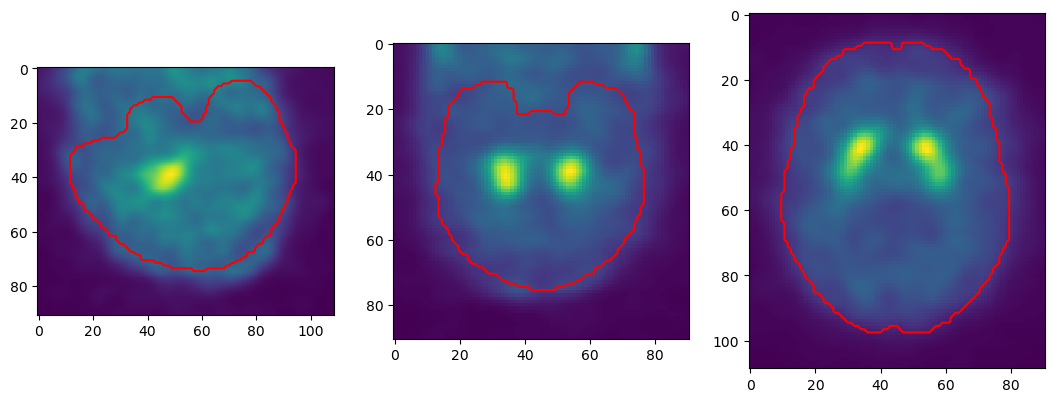

In [ ]:
orVol,_ = load_dicom(df_selected.iloc[90]['dcm_path'])
plt.figure(figsize=(13,6))
plt.subplot(131)
plt.imshow(orVol[:,:,60])
plt.contour(_mask[:,:,60],colors='r')
plt.subplot(132)
plt.imshow(orVol[:,40,:])
plt.contour(_mask[:,40,:],colors='r')
plt.subplot(133)
plt.imshow(orVol[40,:,:])
plt.contour(_mask[40,:,:],colors='r')

## 5. Augmentations

In [19]:
!pip install scikit-image

### 5.1 Define some augmentations

In [20]:
# [AUGMENTATIONS]
    # Define deterministic augmentations to apply one at a time.
    # Each returns a transformed volume (D, H, W) numpy array.

from scipy.ndimage import shift, gaussian_filter

def aug_shift_left(vol):
    return shift(vol, shift=[0, 0, 2], mode='constant', cval=0)

def aug_shift_right(vol):
    return shift(vol, shift=[0, 0, -2], mode='constant', cval=0)

def aug_shift_left_mild(vol):
    return shift(vol, shift=[0, 0, 1], mode='constant', cval=0)

def aug_shift_right_mild(vol):
    return shift(vol, shift=[0, 0, -1], mode='constant', cval=0)

def aug_shift_front_mild(vol):
    return shift(vol, shift=[0, 1, 0], mode='constant', cval=0)

def aug_shift_back_mild(vol):
    return shift(vol, shift=[0, -1, 0], mode='constant', cval=0)

def aug_shift_front(vol):
    return shift(vol, shift=[0, 2, 0], mode='constant', cval=0)

def aug_shift_back(vol):
    return shift(vol, shift=[0, -2, 0], mode='constant', cval=0)

def aug_shift_up(vol):
    return shift(vol, shift=[2, 0, 0], mode='constant', cval=0)

def aug_shift_down(vol):
    return shift(vol, shift=[-2, 0, 0], mode='constant', cval=0)


def aug_intensity_up(vol):
    return vol * 1.1

def aug_intensity_down(vol):
    return vol * 0.9

def aug_flip_lr(vol):
    return np.flip(vol, axis=2).copy()

def aug_gaussian_noise(vol, std=0.3):
    noise = np.random.default_rng(42).normal(0, std, vol.shape).astype(np.float32)
    return vol + noise

def aug_gaussian_smooth(vol, sigma=1.0):
    return gaussian_filter(vol, sigma=sigma).astype(np.float32)

AUGMENTATIONS = {
    'shift_left':       aug_shift_left,
    'shift_right':      aug_shift_right,
    'shift_left_m':     aug_shift_left_mild,
    'shift_right_m':    aug_shift_right_mild,
    'shift_front_m':    aug_shift_front_mild,
    'shift_back_m':     aug_shift_back_mild,
    'shift_front':      aug_shift_front,
    'shift_back':       aug_shift_back,
    'shift_up':         aug_shift_up,
    'shift_down':       aug_shift_down,
    'intensity_up':     aug_intensity_up,
    'intensity_down':   aug_intensity_down,
    'flip_lr':          aug_flip_lr,
    'gaussian_noise':   aug_gaussian_noise,
    'gaussian_smooth':  aug_gaussian_smooth,
}

print(f"Augmentations defined: {list(AUGMENTATIONS.keys())}")

Augmentations defined: ['shift_left', 'shift_right', 'shift_left_m', 'shift_right_m', 'shift_front_m', 'shift_back_m', 'shift_front', 'shift_back', 'shift_up', 'shift_down', 'intensity_up', 'intensity_down', 'flip_lr', 'gaussian_noise', 'gaussian_smooth']


## Image loading routines.
Concept of the order of steps:
1. Load the dicom (prev function) in a numpy. We know it's fixed size. Mask is saved in nifti, needs flippping/permutation. Same matrix size as dicom
2. Normalize the intensity (once, here)
3. Apply the augmentation (BEFORE masking, AFTER normalization)
4. mask/crop. Mask before pad-crop as mask has same size as image

In the current version:

- `load_dicom` reads the volume, correctly, scaling slice by slice the correct way
- `normalize_volume` scales the intensity within the mask, in the original image matrix size
- `vol_to_tensor` masks the image, then crops/pad in numpy using monai, then converts to torch tensor and moves to DEVICE
- `extract_mu` calls `vol_to_tensor` of a numpy volume and then extracts the mus, returns them in numpy

In [21]:
# [AUGMENTATION-LOOP]
    # For each subject and each augmentation:
    #   1. Load original scan → extract mu_original
    #   2. Apply augmentation → extract mu_augmented
    #   3. Compute delta = mu_augmented - mu_original


from tqdm import tqdm

def vol_to_tensor(vol):
    """Apply normalisation + val_transforms to a (91,109,91) array."""
    # vol = normalize_volume(vol)               # ← training-time normalisation
    # print("val_to_tensor", vol.shape)
    vol = vol*_mask
    data = {'image': vol[np.newaxis, ...]}
    val_transforms = Compose([
        SpatialCropd(keys=['image'], roi_slices=[slice(9, 73), slice(None), slice(None)]),
        SpatialPadd(keys=['image'], spatial_size=[64, 128, 128], mode='constant', constant_values=0),
    ])
    data = val_transforms(data)
    tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
    return tensor

def extract_mu(vol):
    tensor = vol_to_tensor(vol)
    with torch.no_grad():
        mu = model.encode(tensor)
    return mu.cpu().numpy()[0]  # (256,)



### Extracts the $\Delta \mu$ on the selected images

In [22]:

results = []

print(f"Running augmentation experiment on {len(df_selected)} subjects...")

for idx, row in tqdm(df_selected.iterrows(), total=len(df_selected)):
    patno    = row['PATNO']
    label    = row['label']
    dcm_path = row['dcm_path']

    try:
        # Use pydicom directly (returns (z,y,x) already)
        vol_or,_ = load_dicom(dcm_path)
        vol_or = normalize_volume(vol_or)

        mu_orig = extract_mu(vol_or.copy())

        for aug_name, aug_fn in AUGMENTATIONS.items():
            vol_aug = aug_fn(vol_or.copy())
            mu_aug  = extract_mu(vol_aug)
            delta   = mu_aug - mu_orig

            for dim_idx in range(len(delta)):
                results.append({
                    'PATNO':   patno,
                    'label':   label,
                    'aug':     aug_name,
                    'dim':     f'latent_{dim_idx}',
                    'delta':   delta[dim_idx],
                    'mu_orig': mu_orig[dim_idx],
                    'mu_aug':  mu_aug[dim_idx],
                })

    except Exception as e:
        print(f"  Skipping {patno}: {e}")

df_delta = pd.DataFrame(results)
print(f"\nDone. Total rows: {len(df_delta)}")
print(df_delta.head())

# Save
os.makedirs('../../results/augmentation', exist_ok=True)
df_delta.to_csv('../../results/augmentation/delta_per_augmentation.csv', index=False)
print("Saved to results/augmentation/delta_per_augmentation.csv")

Running augmentation experiment on 100 subjects...


  0%|          | 0/100 [00:00<?, ?it/s]/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_17785/793660823.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
100%|██████████| 100/100 [09:53<00:00,  5.93s/it]



Done. Total rows: 384000
    PATNO label         aug       dim     delta   mu_orig    mu_aug
0  171091    PD  shift_left  latent_0  0.005582 -0.162231 -0.156648
1  171091    PD  shift_left  latent_1  0.062884  0.020828  0.083712
2  171091    PD  shift_left  latent_2  0.181851  0.712422  0.894273
3  171091    PD  shift_left  latent_3 -0.119335  0.458361  0.339026
4  171091    PD  shift_left  latent_4  0.138788  0.095044  0.233832
Saved to results/augmentation/delta_per_augmentation.csv


### Computes the $<\left \| \Delta \right \| $> 

In [ ]:
# [DELTA-ANALYSIS]
    # For each augmentation, compute mean absolute delta per dimension.
    # High mean |delta| = dimension is sensitive to that augmentation.

# Mean absolute delta per augmentation per dimension
df_mean = (df_delta
           .groupby(['aug', 'dim'])['delta']
           .apply(lambda x: np.abs(x).mean())
           .reset_index()
           .rename(columns={'delta': 'mean_abs_delta'})
           )

# Extract dim index for sorting
df_mean['dim_idx'] = df_mean['dim'].str.replace('latent_', '').astype(int)
df_mean = df_mean.sort_values(['aug', 'dim_idx'])

# Save summary
df_mean.to_csv('../../results/augmentation/mean_abs_delta_per_dim.csv', index=False)

# Top 10 most sensitive dimensions per augmentation
print("Top 10 most sensitive dimensions per augmentation:\n")
for aug_name in AUGMENTATIONS.keys():
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(10, 'mean_abs_delta')[['dim', 'mean_abs_delta']])
    print(f"--- {aug_name} ---")
    print(top.to_string(index=False))
    print()

Top 10 most sensitive dimensions per augmentation:

--- shift_left ---
       dim  mean_abs_delta
latent_222        1.077683
latent_163        0.777869
 latent_83        0.654741
latent_129        0.635741
 latent_17        0.545463
latent_133        0.503060
 latent_86        0.494810
latent_196        0.476715
latent_116        0.449869
latent_206        0.425725

--- shift_right ---
       dim  mean_abs_delta
latent_222        1.069347
latent_163        0.707866
 latent_86        0.652359
latent_129        0.574636
 latent_83        0.508555
latent_196        0.504374
latent_133        0.499300
 latent_17        0.496432
latent_206        0.493718
latent_156        0.454610

--- shift_left_m ---
       dim  mean_abs_delta
latent_222        0.548759
latent_163        0.385356
latent_129        0.314702
 latent_83        0.313898
 latent_17        0.272151
 latent_86        0.271936
latent_133        0.257358
latent_196        0.246099
latent_206        0.226958
latent_116        0.22

In [ ]:
# [TOP-DIM ANALYSIS]
# Cross-reference sensitive dims with KL divergence + PD/HC separation

# ── Top sensitive dims (across all augs combined) ──────────────────────────
top_sensitive = (df_mean.groupby('dim_idx')['mean_abs_delta']
                 .mean()
                 .nlargest(20)
                 .reset_index()
                 .rename(columns={'mean_abs_delta': 'avg_sensitivity'}))

print("Top 20 most sensitive dimensions (averaged across augmentations):")
print(top_sensitive.to_string(index=False))

# ── PD vs HC separation for top sensitive dims ─────────────────────────────
top_dim_indices = top_sensitive['dim_idx'].tolist()

# Get mu_orig for each subject (one row per subject per dim)
df_orig = (df_delta[df_delta['aug'] == 'shift_left']  # any aug, mu_orig is the same
           [['PATNO', 'label', 'dim', 'mu_orig']]
           .copy())
df_orig['dim_idx'] = df_orig['dim'].str.replace('latent_', '').astype(int)
df_orig = df_orig[df_orig['dim_idx'].isin(top_dim_indices)]

# Cohen's d for PD vs HC per dimension
from scipy import stats

separation = []
for dim_idx in top_dim_indices:
    vals = df_orig[df_orig['dim_idx'] == dim_idx]
    pd_vals = vals[vals['label'] == 'PD']['mu_orig'].dropna().values
    hc_vals = vals[vals['label'] == 'HC']['mu_orig'].dropna().values
    
    if len(pd_vals) > 5 and len(hc_vals) > 5:
        t, p = stats.ttest_ind(pd_vals, hc_vals)
        pooled_std = np.sqrt((pd_vals.std()**2 + hc_vals.std()**2) / 2)
        cohens_d = (pd_vals.mean() - hc_vals.mean()) / (pooled_std + 1e-8)
        separation.append({
            'dim_idx': dim_idx,
            'cohens_d': cohens_d,
            'p_value': p,
            'pd_mean': pd_vals.mean(),
            'hc_mean': hc_vals.mean(),
        })
    print(f"dim {dim_idx}: pd_std={pd_vals.std():.4f}, hc_std={hc_vals.std():.4f}, pooled={np.sqrt((pd_vals.std()**2 + hc_vals.std()**2) / 2):.4f}")    

df_sep = pd.DataFrame(separation).sort_values('cohens_d', key=abs, ascending=False)
print("\nPD vs HC separation for top sensitive dims:")
print(df_sep.to_string(index=False))

print("-" * 50)
print("Separation Table")
df_sep = pd.DataFrame(separation).sort_values('cohens_d', key=abs, ascending=False)
print(df_sep.to_string(index=False))


Top 20 most sensitive dimensions (averaged across augmentations):
 dim_idx  avg_sensitivity
     222         0.446757
     171         0.344692
     232         0.328202
     141         0.327313
     129         0.301409
     116         0.295242
     197         0.290063
     218         0.288114
     114         0.265884
     163         0.263525
       7         0.257669
      51         0.253890
     150         0.252613
     173         0.242766
     206         0.239712
      86         0.236494
      83         0.235487
     192         0.233004
      70         0.228172
     228         0.222832
dim 222: pd_std=0.7504, hc_std=0.5735, pooled=0.6678
dim 171: pd_std=0.7982, hc_std=0.6097, pooled=0.7102
dim 232: pd_std=0.8655, hc_std=0.5618, pooled=0.7296
dim 141: pd_std=0.7372, hc_std=0.5263, pooled=0.6405
dim 129: pd_std=0.6079, hc_std=0.6595, pooled=0.6342
dim 116: pd_std=0.6222, hc_std=0.5950, pooled=0.6088
dim 197: pd_std=0.7044, hc_std=0.5346, pooled=0.6253
dim 218: pd_std=0

## 6. Visualization

Top 10 most sensitive dimensions per augmentation:

--- shift_left ---
       dim  mean_abs_delta
latent_222        1.077683
latent_163        0.777869
 latent_83        0.654741
latent_129        0.635741
 latent_17        0.545463
latent_133        0.503060
 latent_86        0.494810
latent_196        0.476715
latent_116        0.449869
latent_206        0.425725

--- shift_right ---
       dim  mean_abs_delta
latent_222        1.069347
latent_163        0.707866
 latent_86        0.652359
latent_129        0.574636
 latent_83        0.508555
latent_196        0.504374
latent_133        0.499300
 latent_17        0.496432
latent_206        0.493718
latent_156        0.454610

--- shift_left_m ---
       dim  mean_abs_delta
latent_222        0.548759
latent_163        0.385356
latent_129        0.314702
 latent_83        0.313898
 latent_17        0.272151
 latent_86        0.271936
latent_133        0.257358
latent_196        0.246099
latent_206        0.226958
latent_116        0.22

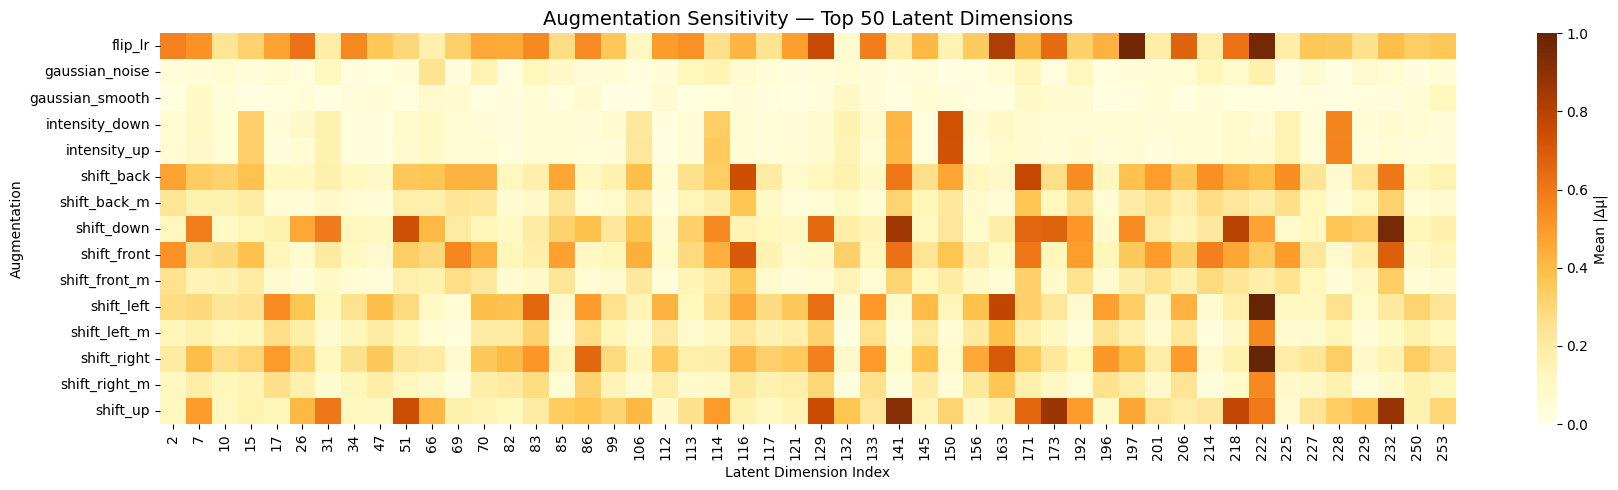

Saved heatmap.


In [ ]:

# ── 2. Top 10 per augmentation ─────────────────────────────────────────────
print("Top 10 most sensitive dimensions per augmentation:\n")
for aug_name in AUGMENTATIONS.keys():
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(10, 'mean_abs_delta')[['dim', 'mean_abs_delta']])
    print(f"--- {aug_name} ---")
    print(top.to_string(index=False))
    print()

# ── 3. Pivot for heatmap (aug × dim) ──────────────────────────────────────
pivot = df_mean.pivot(index='aug', columns='dim_idx', values='mean_abs_delta')

# ── 4. Plot: show only top 50 most sensitive dims (across all augs) ────────
top_dims = df_mean.groupby('dim_idx')['mean_abs_delta'].mean().nlargest(50).index
pivot_top = pivot[top_dims.sort_values()]

fig, ax = plt.subplots(figsize=(18, 5))
sns.heatmap(pivot_top, ax=ax, vmin=0,vmax=1,cmap='YlOrBr', linewidths=0,
            cbar_kws={'label': 'Mean |Δμ|'})
ax.set_title('Augmentation Sensitivity — Top 50 Latent Dimensions', fontsize=14)
ax.set_xlabel('Latent Dimension Index')
ax.set_ylabel('Augmentation')
plt.tight_layout()
plt.savefig('../../results/augmentation/sensitivity_heatmap.png', dpi=150)
plt.show()
print("Saved heatmap.")

# ── 5. Save summary ────────────────────────────────────────────────────────
df_mean.to_csv('../../results/augmentation/mean_abs_delta_per_dim.csv', index=False)

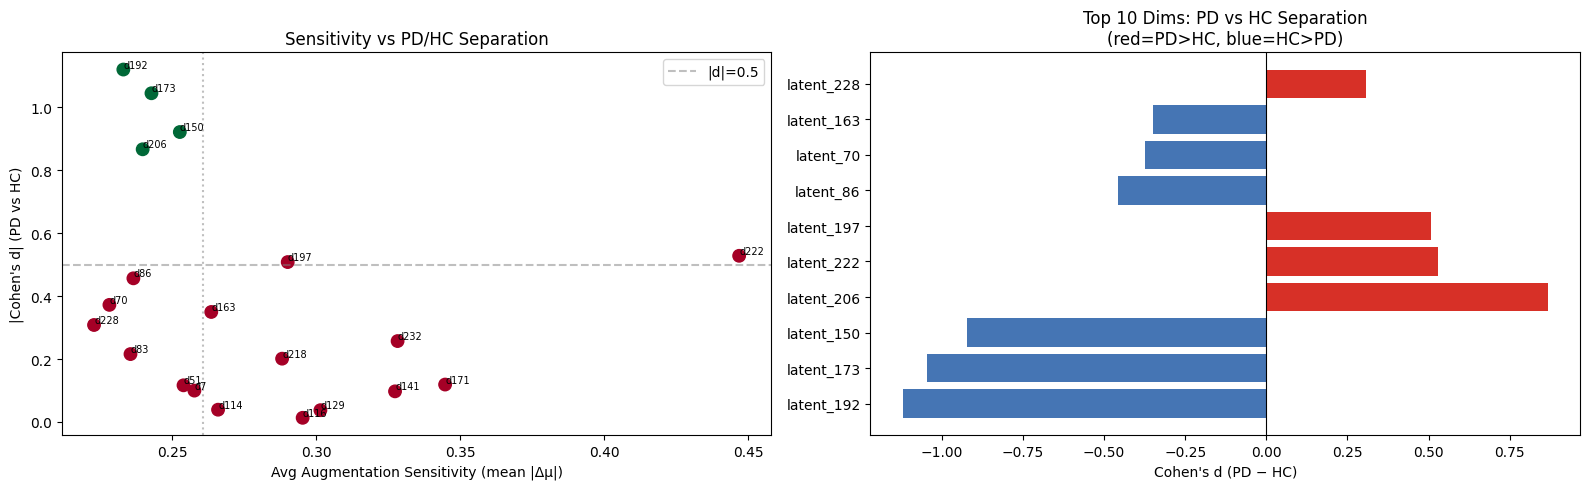

In [ ]:
# [COMBINED PLOT: sensitivity vs PD/HC separation]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: scatter — sensitivity vs |Cohen's d|
ax = axes[0]
merged = top_sensitive.merge(df_sep, on='dim_idx')
ax.scatter(merged['avg_sensitivity'], merged['cohens_d'].abs(),
           c=merged['p_value'] < 0.05, cmap='RdYlGn', s=80)
for _, r in merged.iterrows():
    ax.annotate(f"d{int(r['dim_idx'])}", (r['avg_sensitivity'], abs(r['cohens_d'])),
                fontsize=7, ha='left', va='bottom')
ax.set_xlabel('Avg Augmentation Sensitivity (mean |Δμ|)')
ax.set_ylabel("|Cohen's d| (PD vs HC)")
ax.set_title('Sensitivity vs PD/HC Separation')
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='|d|=0.5')
ax.axvline(merged['avg_sensitivity'].median(), color='gray', linestyle=':', alpha=0.5)
ax.legend()

# Right: bar — top 10 dims by |Cohen's d|, coloured by direction
ax = axes[1]
top10_sep = df_sep.nlargest(10, 'cohens_d', keep='all').head(10)
top10_sep = df_sep.reindex(df_sep['cohens_d'].abs().nlargest(10).index)
colors = ['#d73027' if d > 0 else '#4575b4' for d in top10_sep['cohens_d']]
ax.barh(top10_sep['dim_idx'].astype(str).apply(lambda x: f'latent_{x}'),
        top10_sep['cohens_d'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel("Cohen's d (PD − HC)")
ax.set_title("Top 10 Dims: PD vs HC Separation\n(red=PD>HC, blue=HC>PD)")

plt.tight_layout()
plt.savefig('../../results/augmentation/sensitivity_vs_separation.png', dpi=150)
plt.show()

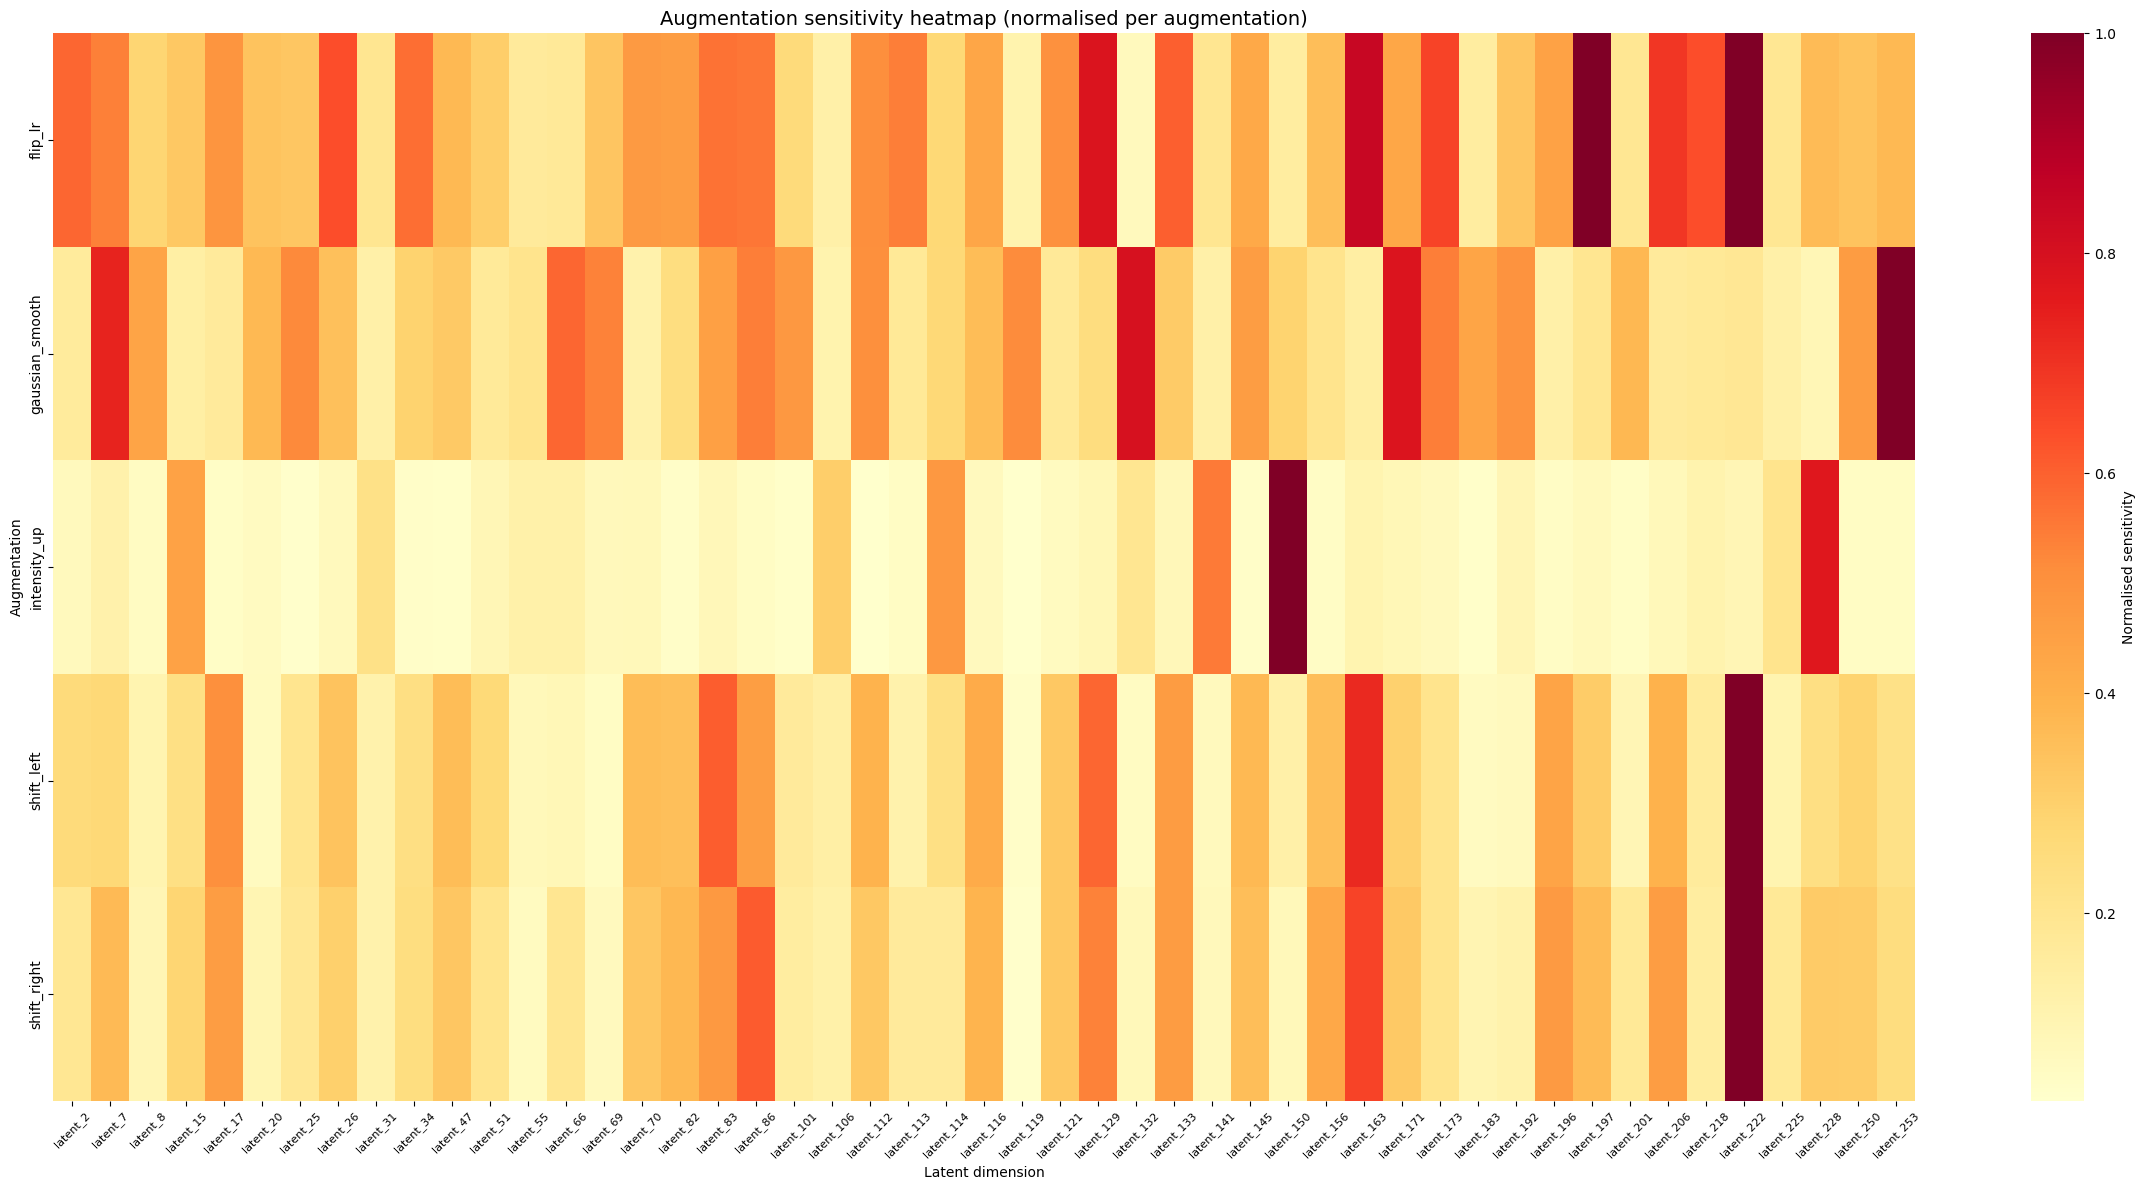

Saved.


In [ ]:
# [VISUALISATION]
# Heatmap: augmentation × top sensitive dimensions

# Collect top 20 dims across all augmentations (excluding gaussian_noise)
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

top_dims = set()
for aug_name in augs_to_plot:
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(20, 'mean_abs_delta')['dim'].tolist())
    top_dims.update(top)

# Always include key dims
top_dims.update(['latent_132', 'latent_173', 'latent_114', 'latent_218'])
top_dims = sorted(top_dims, key=lambda x: int(x.replace('latent_', '')))

# Pivot table
df_heatmap = (df_mean[df_mean['aug'].isin(augs_to_plot)]
              .pivot(index='aug', columns='dim', values='mean_abs_delta')
              [top_dims])

# Normalise per augmentation row (0-1)
df_norm = df_heatmap.div(df_heatmap.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(24, 12))
sns.heatmap(df_norm, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Normalised sensitivity'})
ax.set_title('Augmentation sensitivity heatmap (normalised per augmentation)', fontsize=14)
ax.set_xlabel('Latent dimension')
ax.set_ylabel('Augmentation')
plt.xticks(rotation=45, fontsize=8)
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_sensitivity_heatmap.png', dpi=150)
plt.show()
print("Saved.")

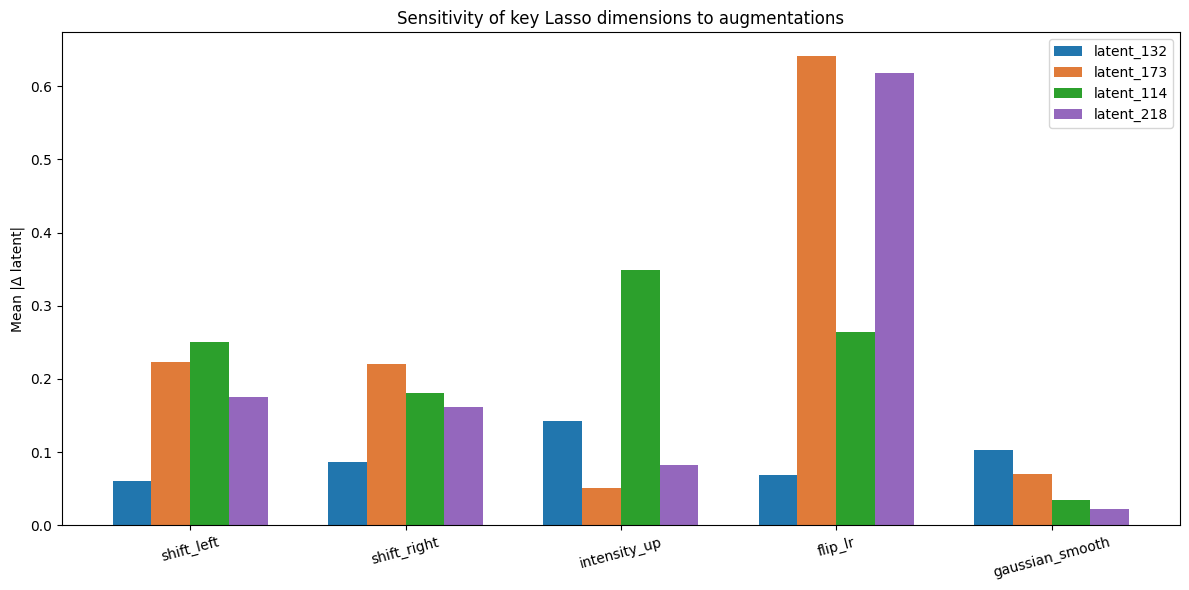

Saved.


In [ ]:
# [KEY-DIMS-PLOT]
# ─────────────────────────────────────────────────────────────────
# Bar plot: sensitivity of key Lasso dimensions per augmentation
# ─────────────────────────────────────────────────────────────────

key_dims = ['latent_132', 'latent_173', 'latent_114', 'latent_218']
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

df_key = df_mean[
    df_mean['dim'].isin(key_dims) &
    df_mean['aug'].isin(augs_to_plot)
].copy()

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(augs_to_plot))
width = 0.18
colors = ['#2176ae', '#e07b39', '#2ca02c', '#9467bd']

for i, dim in enumerate(key_dims):
    vals = [df_key[(df_key['aug'] == aug) & (df_key['dim'] == dim)]['mean_abs_delta'].values[0]
            for aug in augs_to_plot]
    ax.bar(x + i * width, vals, width, label=dim, color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(augs_to_plot, rotation=15)
ax.set_ylabel('Mean |Δ latent|')
ax.set_title('Sensitivity of key Lasso dimensions to augmentations')
ax.legend()
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_top_dims.png', dpi=150)
plt.show()
print("Saved.")

## 7. Sanity Check

This has to be run using the same identical function as in model calling! otherwhise it's not checking!

In [ ]:

# encode → decode
results_rc = []
with torch.no_grad():
    for idx, row in tqdm(df_selected.iterrows(), total=len(df_selected)):
        patno    = row['PATNO']
        label    = row['label']
        dcm_path = row['dcm_path']
        vol_or,_ = load_dicom(dcm_path)
        vol_or = normalize_volume(vol_or)
        vol = vol_to_tensor(vol_or)
        recon, mu = model(vol)          # model is the VAEWrapper already loaded
        orig_np  = vol[0, 0].cpu().numpy()
        recon_np = recon[0, 0].cpu().numpy()
        mse = np.mean((orig_np - recon_np) ** 2)
        print(f"  {row['label']}  {row['PATNO'][:16]:16s}  MSE={mse:.4f}  "
            f"μ range [{mu.min():.2f}, {mu.max():.2f}]")
        results_rc.append({**row, 'orig': orig_np, 'recon': recon_np, 'mse': mse})

  3%|██▋                                                                                       | 3/100 [00:00<00:10,  9.44it/s]

  PD  239077            MSE=0.0074  μ range [-2.90, 1.91]
  PD  40733             MSE=0.0061  μ range [-1.80, 1.80]
  PD  243614            MSE=0.0060  μ range [-2.35, 1.82]
  PD  4035              MSE=0.0059  μ range [-1.88, 1.66]


 10%|████████▉                                                                                | 10/100 [00:00<00:04, 20.11it/s]

  PD  3787              MSE=0.0056  μ range [-1.78, 1.38]
  PD  128590            MSE=0.0085  μ range [-1.76, 1.63]
  PD  5004              MSE=0.0046  μ range [-2.10, 1.80]
  PD  292873            MSE=0.0053  μ range [-1.50, 1.52]
  PD  3856              MSE=0.0069  μ range [-1.27, 2.27]
  PD  301951            MSE=0.0070  μ range [-2.10, 2.01]


 14%|████████████▍                                                                            | 14/100 [00:00<00:03, 24.45it/s]

  PD  190336            MSE=0.0061  μ range [-1.96, 2.23]
  PD  56405             MSE=0.0055  μ range [-1.10, 1.96]
  PD  3360              MSE=0.0074  μ range [-2.17, 1.58]
  PD  59398             MSE=0.0061  μ range [-0.95, 1.39]
  PD  165031            MSE=0.0076  μ range [-2.96, 4.28]
  PD  4117              MSE=0.0058  μ range [-1.50, 1.93]
  PD  174213            MSE=0.0069  μ range [-2.61, 1.93]


... (24 outputs left out)

 92%|█████████████████████████████████████████████████████████████████████████████████▉       | 92/100 [00:03<00:00, 25.40it/s]

  HC  3855              MSE=0.0063  μ range [-1.99, 2.27]
  HC  293057            MSE=0.0052  μ range [-1.92, 1.76]
  SWEDD  3441              MSE=0.0050  μ range [-1.69, 2.25]
  SWEDD  3022              MSE=0.0065  μ range [-1.61, 1.92]
  SWEDD  3381              MSE=0.0063  μ range [-2.35, 2.28]
  SWEDD  3456              MSE=0.0058  μ range [-1.24, 1.97]


100%|████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:03<00:00, 25.32it/s]

  SWEDD  3324              MSE=0.0063  μ range [-2.35, 2.35]
  SWEDD  3426              MSE=0.0063  μ range [-1.58, 1.93]
  SWEDD  3255              MSE=0.0052  μ range [-1.45, 2.24]
  SWEDD  4031              MSE=0.0048  μ range [-1.70, 2.06]
  SWEDD  3101              MSE=0.0069  μ range [-1.40, 1.80]
  SWEDD  3262              MSE=0.0064  μ range [-1.60, 2.13]


Saved → results/figures/reconstruction_sanity_check_v2.png


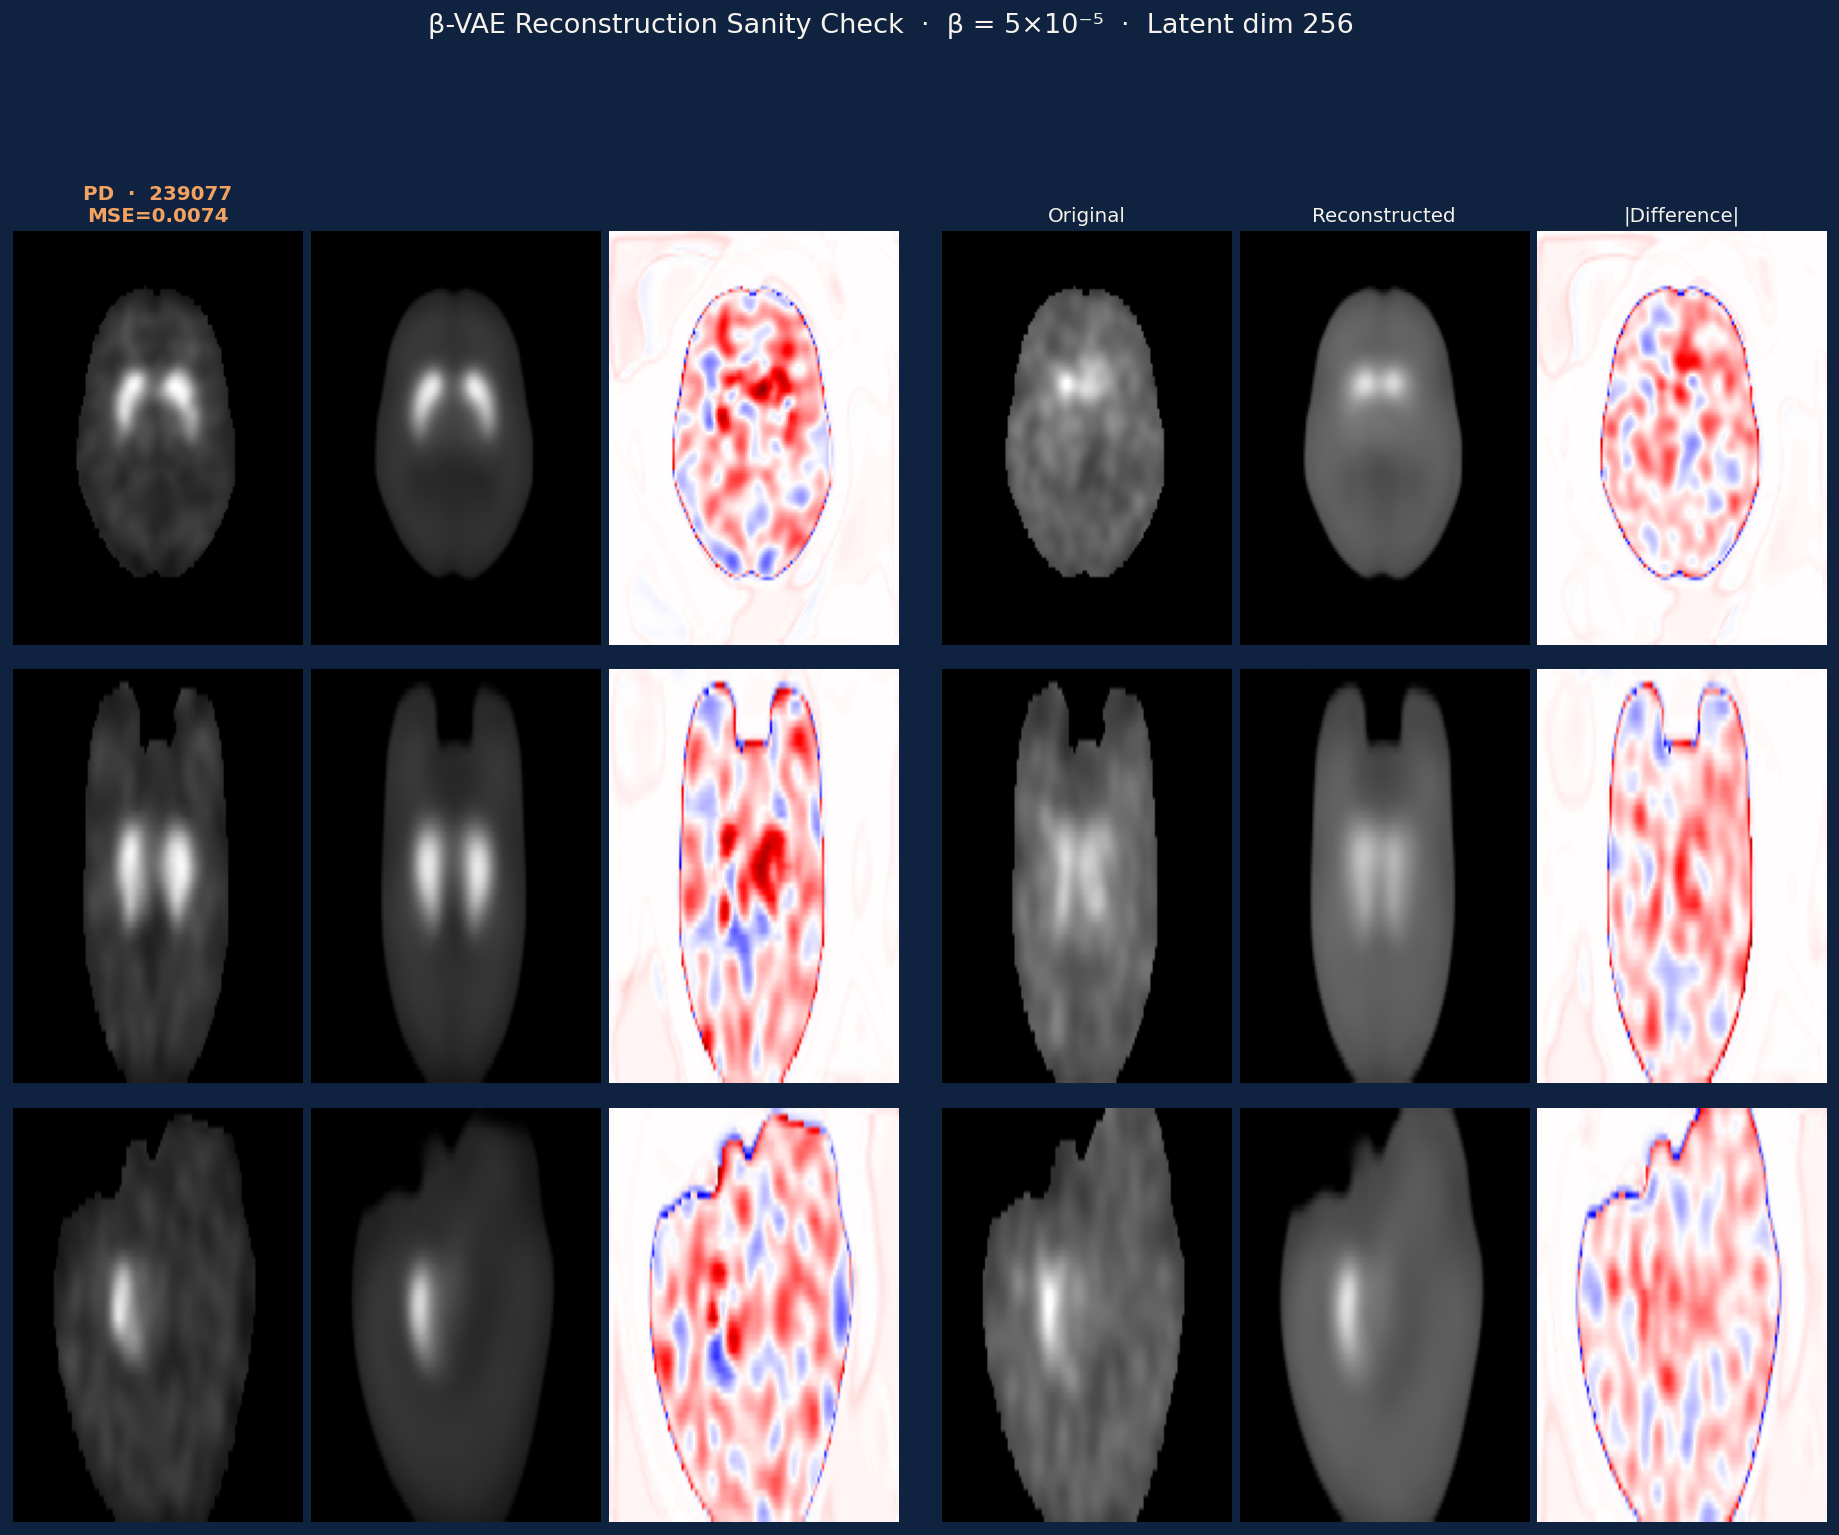

In [ ]:
import matplotlib.gridspec as gridspec

# Plot
N =  2  #len(results_rc)
fig = plt.figure(figsize=(N * 9, 3 * 3.8 + 1.5), facecolor='#0F2240')
outer = gridspec.GridSpec(1, N, figure=fig, wspace=0.05)

def get_slices(vol):
    # vol shape: (64, 128, 128) = (z, y, x) after crop+pad
    # z=30 → original z≈39 → striatal level (caudate/putamen)
    mid_z = 30
    mid_y = 50 # vol.shape[1] // 2   # 64
    mid_x = 55 #vol.shape[2] // 2   # 64
    return [
        vol[mid_z, :, :],    # axial  — wide oval, two hotspots
        vol[:, mid_y, :],    # coronal
        vol[:, :, mid_x],    # sagittal
    ]

slice_labels = ['Axial\n(striatum)', 'Coronal', 'Sagittal']

for si, res in enumerate(results_rc[:N]):
    inner = gridspec.GridSpecFromSubplotSpec(3, 3, subplot_spec=outer[si],
                                             wspace=0.03, hspace=0.06)
    os_ = get_slices(res['orig'])
    rs_ = get_slices(res['recon'])
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'
    vmax = (max(res['orig'].max(), res['recon'].max()) + 1e-8)*.98
    for row, (o, r, sl) in enumerate(zip(os_, rs_, slice_labels)):
        diff =(o - r)
        
        for col, (img, cmap) in enumerate([(o,'gray'), (r,'gray'), (diff,'seismic')]):
            ax = fig.add_subplot(inner[row, col])
            ax.imshow(img, cmap=cmap, vmin=0 if col < 2 else -1,
                      vmax=vmax if col < 2 else 1, aspect='auto')
            ax.axis('off')
            if col == 0 and row == 0:
                titles = ['Original', 'Reconstructed', '|Difference|']
                ax.set_title(f"{res['label']}  ·  {res['PATNO'][:14]}\nMSE={res['mse']:.4f}",
                             fontsize=11, color=lc, pad=5, fontweight='bold')
            if col == 0:
                ax.set_ylabel(sl, fontsize=9, color='#A8C0C0',
                              rotation=0, labelpad=50, va='center')

# column headers on middle subject
mid = N // 2
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    ax0 = fig.axes[mid * 9 + col]     # first row axes for middle subject
    ax0.set_title(title, fontsize=11, color='#F5F2EC', pad=5)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=15, color='#F5F2EC', y=1.01, fontweight='300')
plt.savefig(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'),
            dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()
print("Saved → results/figures/reconstruction_sanity_check_v2.png")
from IPython.display import Image, display
with open(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'), 'rb') as f:
    display(Image(data=f.read()))

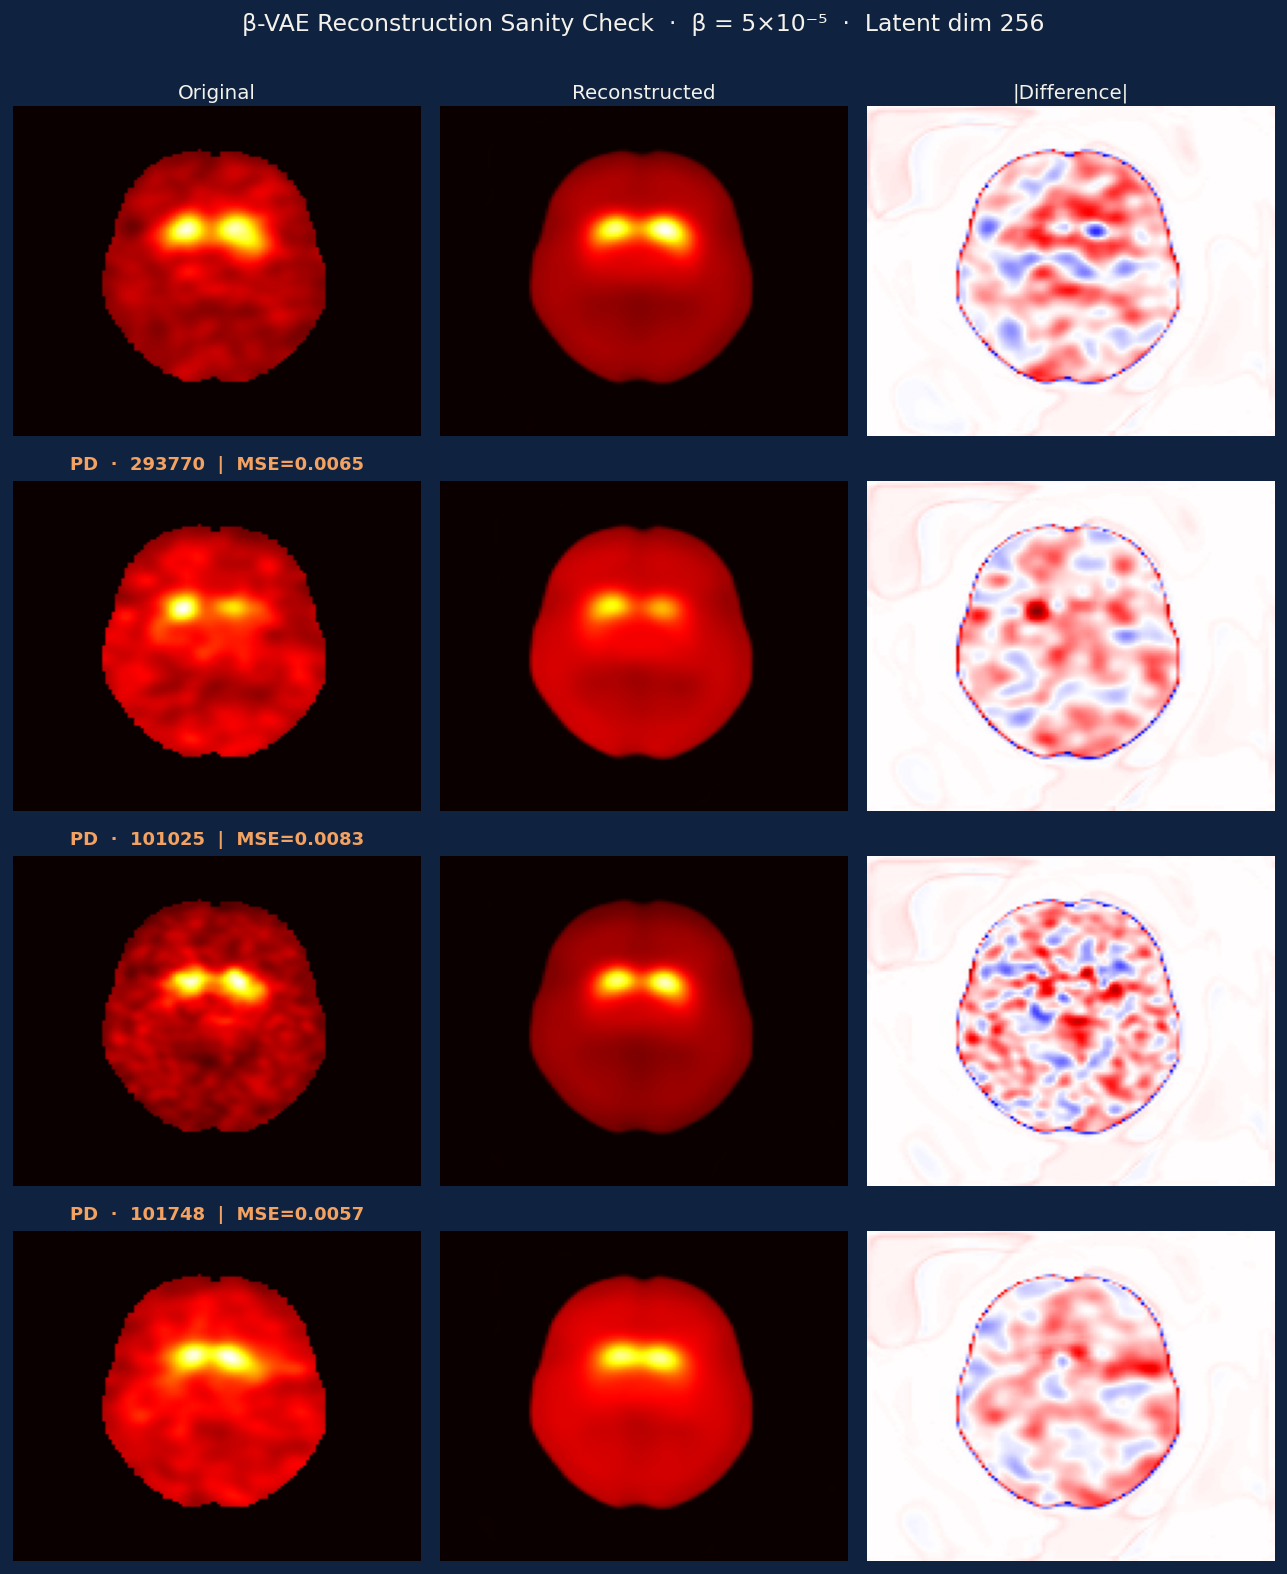

In [ ]:
import random
N_imm = 4

fig, axes = plt.subplots(N_imm, 3, figsize=(10, 3 * N_imm),
                         facecolor='#0F2240')
axes = np.array(axes)

for si, res in enumerate(random.sample(results_rc,N_imm)):
    o = res['orig'][30, :, :]
    r = res['recon'][30, :, :]
    d = (o - r)
    vmax = max(o.max(), r.max()) + 1e-8
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'

    axes[si, 0].imshow(o, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 0].set_title(f"{res['label']}  ·  {res['PATNO'][:10]}  |  MSE={res['mse']:.4f}",
                          color=lc, fontsize=10, fontweight='bold')
    axes[si, 0].set_ylabel('Axial z=30\n(striatum)', color='#A8C0C0', fontsize=8,
                            rotation=0, labelpad=55, va='center')
    axes[si, 0].axis('off')

    axes[si, 1].imshow(r, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 1].axis('off')

    axes[si, 2].imshow(d, cmap='seismic',vmin=-1, vmax=1, aspect='auto')
    axes[si, 2].axis('off')

# Column headers on row 0 only
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    axes[0, col].set_title(title, color='#F5F2EC', fontsize=11, pad=4)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=13, color='#F5F2EC', y=1.005, fontweight='300')

plt.tight_layout()
out_path = os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v3.png')
plt.savefig(out_path, dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()

from IPython.display import Image, display
with open(out_path, 'rb') as f:
    display(Image(data=f.read()))